In [105]:
##This is a pytorch implement for HybridSN 
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchinfo import summary
import numpy as np
import matplotlib.pyplot as plt
import spectral
import random
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report,recall_score,cohen_kappa_score,accuracy_score
from scipy.io import loadmat
import os
from tqdm.notebook import tqdm
%matplotlib inline

In [106]:
##hypeperameters and experimental settings
RANDOM_SEED=666
DATASET = 'PU'    ## PU  IP  SA  
TRAIN_RATE = 0.3  ## ratio of training data
VAL_RATE = 0.1    ## ratio of valuating data
EPOCH = 100    ##number of epoch
VAL_EPOCH = 5  ##interval of valuation
LR = 0.001    ##learning rate
WEIGHT_DECAY = 1e-6  
BATCH_SIZE = 256
DEVICE = 0  ##-1:CPU  0:cuda 0
N_PCA = 15  ## reserved PCA components
PATCH_SIZE = 25 
SAVE_PATH = f"results\\{DATASET}_opt2b_mask11"
if not os.path.isdir(SAVE_PATH):
    os.mkdir(SAVE_PATH)

In [107]:
## Set random seed for reproduction
random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
torch.cuda.manual_seed(RANDOM_SEED)
torch.cuda.manual_seed_all(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [108]:
def loadData(name):
    data_path = os.path.join(os.getcwd(),'dataset')
    if name == 'IP':
        data = loadmat(os.path.join(data_path, 'IndianPines\\Indian_pines_corrected.mat'))['indian_pines_corrected']
        labels = loadmat(os.path.join(data_path, 'IndianPines\\Indian_pines_gt.mat'))['indian_pines_gt']
        class_name = [ "Alfalfa", "Corn-notill", "Corn-mintill","Corn", "Grass-pasture", 
                       "Grass-trees","Grass-pasture-mowed", "Hay-windrowed", "Oats","Soybean-notill", "Soybean-mintill", "Soybean-clean","Wheat", "Woods", "Buildings-Grass-Trees-Drives","Stone-Steel-Towers"]
    elif name == 'SA':
        data = loadmat(os.path.join(data_path, 'Salinas\\Salinas_corrected.mat'))['salinas_corrected']
        labels = loadmat(os.path.join(data_path, 'Salinas\\Salinas_gt.mat'))['salinas_gt']
        class_name = ['Brocoli_green_weeds_1','Brocoli_green_weeds_2','Fallow',
                        'Fallow_rough_plow','Fallow_smooth','Stubble','Celery','Grapes_untrained','Soil_vinyard_develop','Corn_senesced_green','Lettuce_romaine_4wk','Lettuce_romaine_5wk','Lettuce_romaine_6wk','Lettuce_romaine_7wk','Vinyard_untrained','Vinyard_vertical']
    elif name == 'PU':
        data = loadmat(os.path.join(data_path, 'PaviaU\\PaviaU.mat'))['paviaU']
        labels = loadmat(os.path.join(data_path, 'PaviaU\\PaviaU_gt.mat'))['paviaU_gt']
        class_name = ['Asphalt', 'Meadows', 'Gravel', 'Trees','Painted metal sheets', 'Bare Soil', 
                      'Bitumen','Self-Blocking Bricks', 'Shadows']
    return data, labels, class_name


In [109]:
data,label,class_name = loadData(DATASET)
NUM_CLASS = label.max()

<site-packages>\spectral\graphics\spypylab.py:796: UserWarning: Failed to create RectangleSelector object. Interactive pixel class labeling will be unavailable.
  warnings.warn(msg)


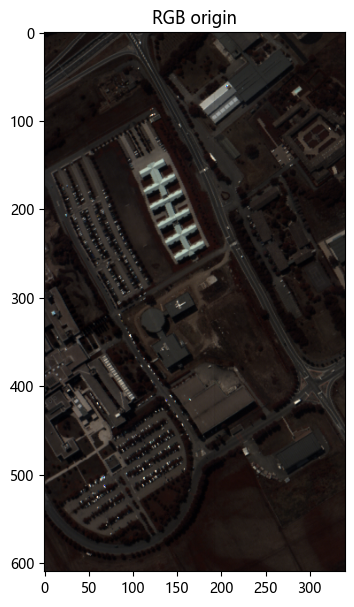

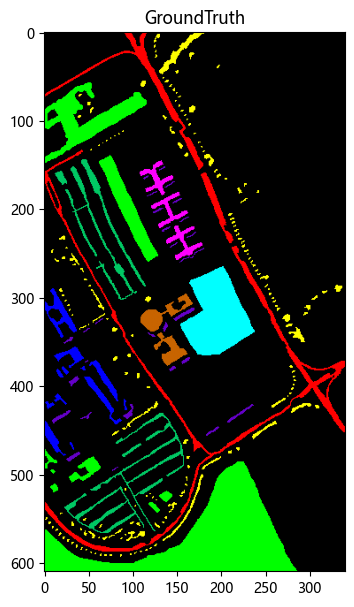

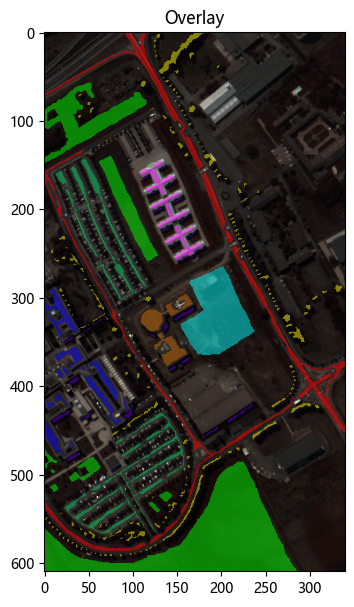

In [110]:
## display HSI
rgb_view=spectral.imshow(data,(30,20,10),classes=label,title='RGB origin',figsize=(7,7))
gt_view = spectral.imshow(classes=label, title='GroundTruth',figsize=(7,7))
view = spectral.imshow(data,(30,20,10),classes=label,figsize=(7,7))
view.set_display_mode('overlay')
view.class_alpha = 0.5
view.set_title('Overlay')
spectral.save_rgb(f'results/{DATASET}_RGB_origin.jpg',data,(30,20,10))
spectral.save_rgb(f'results/{DATASET}_gt.jpg',label,colors = spectral.spy_colors)

原始数据立方体: (610, 340, 103)    波段数 B = 103    类别数 = 9

类间光谱角（度）—— 数值越小说明两类光谱越相似、越容易混
                             Asphalt   Meadows    Gravel     Trees  Painted   Bare Soi   Bitumen  Self-Blo   Shadows
Asphalt                         0.00     28.36      3.28     43.04     18.94     17.96      1.81      3.09     23.67
Meadows                        28.36      0.00     27.29     15.74     41.86     11.03     29.82     27.13     26.63
Gravel                          3.28     27.29      0.00     42.36     21.82     16.52      4.18      0.96     25.30
Trees                          43.04     15.74     42.36      0.00     53.83     26.53     44.48     42.16     34.75
Painted metal sheets           18.94     41.86     21.82     53.83      0.00     33.66     17.90     21.43     28.86
Bare Soil                      17.96     11.03     16.52     26.53     33.66      0.00     19.39     16.37     24.21
Bitumen                         1.81     29.82      4.18     44.48     17.90     19.39      0.00   

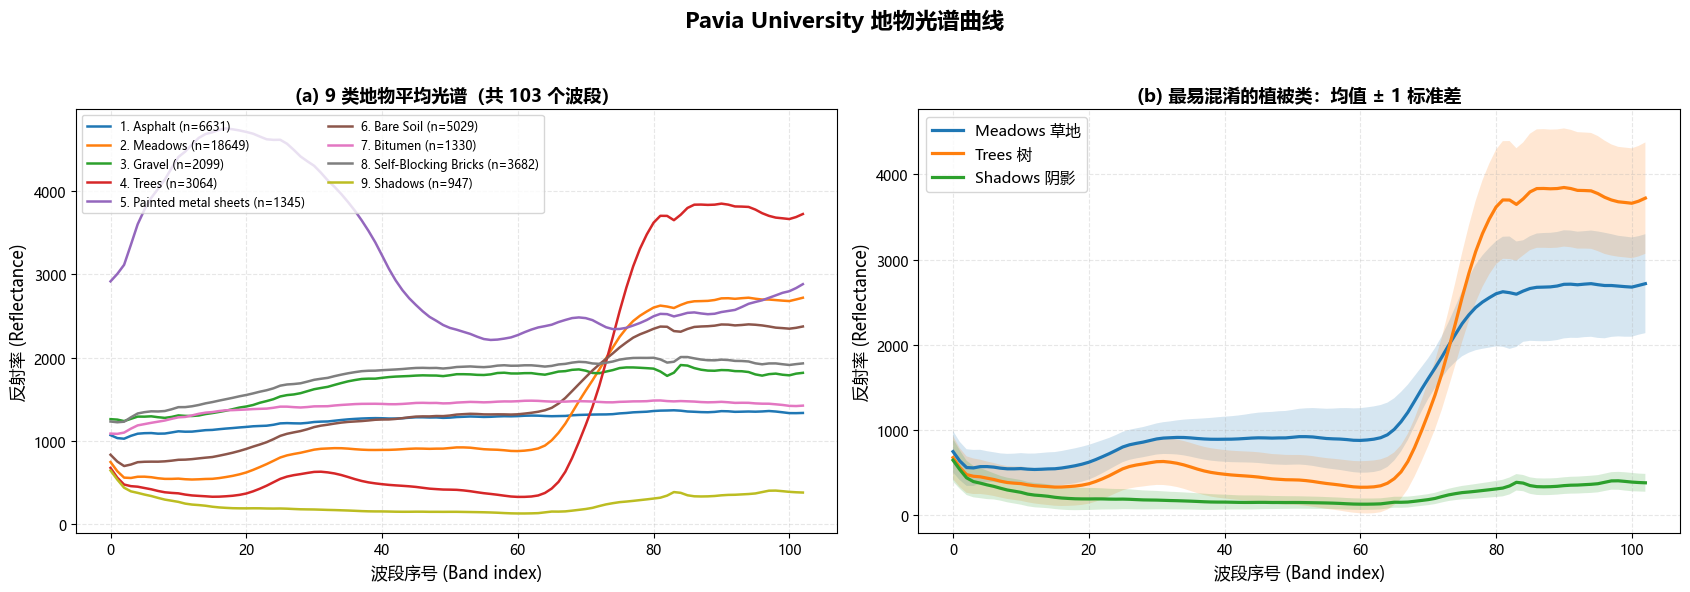

In [111]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

B = data.shape[2]
assert B > 20, f"波段数只有 {B}，说明 data 已被 PCA 覆盖！本单元格必须在 applyPCA 之前运行"

print(f"原始数据立方体: {data.shape}    波段数 B = {B}    类别数 = {NUM_CLASS}")

# ---------- 计算各类的平均光谱 ----------
spectra_list, means, counts = [], [], []
for c in range(1, NUM_CLASS + 1):
    idx = np.nonzero(label == c)
    sp = data[idx[0], idx[1], :]           # (该类像元数, B)
    spectra_list.append(sp)
    means.append(sp.mean(axis=0))
    counts.append(len(idx[0]))
means = np.array(means)

# ---------- 画图 ----------
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
fig.suptitle('Pavia University 地物光谱曲线', fontsize=16, fontweight='bold')
cmap = plt.get_cmap('tab10')

# (a) 9 类平均光谱
ax = axes[0]
for c in range(1, NUM_CLASS + 1):
    ax.plot(np.arange(B), means[c - 1], lw=1.8, color=cmap((c - 1) % 10),
            label=f"{c}. {class_name[c-1]} (n={counts[c-1]})")
ax.set_xlabel('波段序号 (Band index)', fontsize=12)
ax.set_ylabel('反射率 (Reflectance)', fontsize=12)
ax.set_title(f'(a) 9 类地物平均光谱（共 {B} 个波段）', fontsize=13, fontweight='bold')
ax.grid(alpha=0.3, ls='--')
ax.legend(fontsize=8.5, loc='upper left', ncol=2)

# (b) 聚焦最易混淆的植被类
ax = axes[1]
FOCUS = {2: 'Meadows 草地', 4: 'Trees 树', 9: 'Shadows 阴影'}
for c, nm in FOCUS.items():
    mu, sd = means[c - 1], spectra_list[c - 1].std(axis=0)
    ax.plot(np.arange(B), mu, lw=2.3, label=nm)
    ax.fill_between(np.arange(B), mu - sd, mu + sd, alpha=0.18)
ax.set_xlabel('波段序号 (Band index)', fontsize=12)
ax.set_ylabel('反射率 (Reflectance)', fontsize=12)
ax.set_title('(b) 最易混淆的植被类：均值 ± 1 标准差', fontsize=13, fontweight='bold')
ax.grid(alpha=0.3, ls='--')
ax.legend(fontsize=11)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('results/spectral_curves.png', dpi=150, bbox_inches='tight')

# ---------- 类间光谱相似度（光谱角，越小越像）----------
def spec_angle(a, b):
    cos = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
    return np.degrees(np.arccos(np.clip(cos, -1, 1)))

ang = np.array([[spec_angle(means[i], means[j]) for j in range(NUM_CLASS)]
                for i in range(NUM_CLASS)])

print("\n" + "=" * 66)
print("类间光谱角（度）—— 数值越小说明两类光谱越相似、越容易混")
print("=" * 66)
print(" " * 26 + "".join(f"{n[:8]:>10}" for n in class_name))
for i, n in enumerate(class_name):
    print(f"{n:<26}" + "".join(f"{ang[i, j]:>10.2f}" for j in range(NUM_CLASS)))

np.fill_diagonal(ang, np.inf)
print("\n最相似（最容易混）的 5 对：")
flat = [(ang[i, j], i, j) for i in range(NUM_CLASS) for j in range(i + 1, NUM_CLASS)]
for a, i, j in sorted(flat)[:5]:
    print(f"   {class_name[i]:<22} ↔ {class_name[j]:<22} 光谱角 = {a:.2f}°")

In [112]:
## show 3D cube
# %matplotlib auto
# spectral.view_cube(data,(30,20,10))   ## depend on wxpython and pyopengl

In [113]:
def applyPCA(X, numComponents=15):
    """PCA processing

    Args:
        X (ndarray M*N*C): data needs DR
        numComponents (int, optional): number of reserved components. Defaults to 15.

    Returns:
        newX: _description_
    """
    newX = np.reshape(X, (-1, X.shape[2]))
    pca = PCA(n_components=numComponents, whiten=True)   ##PCA and normalization
    newX = pca.fit_transform(newX)
    newX = np.reshape(newX, (X.shape[0],X.shape[1], numComponents))
    return newX, pca

In [114]:
data,pca = applyPCA(data,N_PCA)
data.shape

(610, 340, 15)

In [115]:
def sample_gt(gt, train_rate):
    """ generate training gt for training dataset
    Args:
        gt (ndarray): full classmap
        train_rate (float): ratio of training dataset
    Returns:
        train_gt(ndarray): classmap of training data
        test_gt(ndarray): classmap of test data
    """
    indices = np.nonzero(gt)  ##([x1,x2,...],[y1,y2,...])
    X = list(zip(*indices))  ## X=[(x1,y1),(x2,y2),...] location of pixels
    y = gt[indices].ravel()
    train_gt = np.zeros_like(gt)
    test_gt = np.zeros_like(gt)
    if train_rate > 1:
       train_rate = int(train_rate)
    train_indices, test_indices = train_test_split(X, train_size=train_rate, stratify=y, random_state=100)
    train_indices = [t for t in zip(*train_indices)]   ##[[x1,x2,...],[y1,y2,...]]
    test_indices = [t for t in zip(*test_indices)]
    train_gt[tuple(train_indices)] = gt[tuple(train_indices)]
    test_gt[tuple(test_indices)] = gt[tuple(test_indices)]
    
    return train_gt, test_gt

In [116]:
train_gt, test_gt = sample_gt(label,TRAIN_RATE)
val_gt,test_gt = sample_gt(test_gt,VAL_RATE/(1-TRAIN_RATE))

  class   train_num  val_num   test_num   total   
    1        1989      663       3979      6631   
    2        5594      1865     11190     18649   
    3        630       210       1259      2099   
    4        919       306       1839      3064   
    5        403       134       808       1345   
    6        1509      503       3017      5029   
    7        399       133       798       1330   
    8        1105      368       2209      3682   
    9        284        95       568       947    
  total     12832      4277     25667     42776   


<site-packages>\spectral\graphics\spypylab.py:796: UserWarning: Failed to create RectangleSelector object. Interactive pixel class labeling will be unavailable.
  warnings.warn(msg)


ImageView object:
  Interpolation       :  <default>

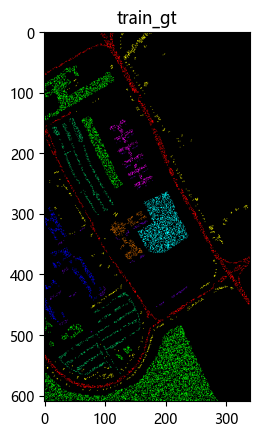

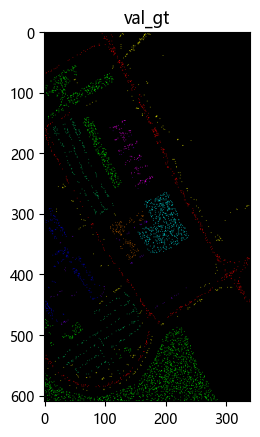

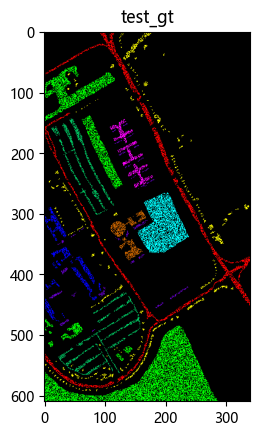

In [117]:
## display sampling info
sample_report = f"{'class': ^10}{'train_num':^10}{'val_num': ^10}{'test_num': ^10}{'total': ^10}\n"
for i in np.unique(label):
    if i == 0: continue
    sample_report += f"{i: ^10}{(train_gt==i).sum(): ^10}{(val_gt==i).sum(): ^10}{(test_gt==i).sum(): ^10}{(label==i).sum(): ^10}\n"
sample_report += f"{'total': ^10}{np.count_nonzero(train_gt): ^10}{np.count_nonzero(val_gt): ^10}{np.count_nonzero(test_gt): ^10}{np.count_nonzero(label): ^10}"
print(sample_report)
spectral.imshow(classes=train_gt, title='train_gt')
spectral.imshow(classes=val_gt, title='val_gt')
spectral.imshow(classes=test_gt, title='test_gt')

In [118]:
class PatchSet(Dataset):
    """ Generate 3D patch from hyperspectral dataset """
    def __init__(self, data, gt, patch_size, is_pred=False):
        """
        Args:
            data: 3D hyperspectral image
            gt: 2D array of labels
            patch_size: int, size of the 3D patch
            is_pred: bool, create data without label for prediction (default False) 

        """
        super(PatchSet, self).__init__()
        self.is_pred = is_pred
        self.patch_size = patch_size
        p = self.patch_size // 2
        self.data = np.pad(data,((p,p),(p,p),(0,0)),'constant',constant_values = 0)
        if is_pred:
            gt = np.ones_like(gt)
        self.label = np.pad(gt,(p,p),'constant',constant_values = 0)
        x_pos, y_pos = np.nonzero(gt)
        x_pos, y_pos = x_pos + p, y_pos + p   ##indices after padding
        self.indices = np.array([(x,y) for x,y in zip(x_pos, y_pos)])
        if not is_pred:
            np.random.shuffle(self.indices)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        x, y = self.indices[i]
        x1, y1 = x - self.patch_size // 2, y - self.patch_size // 2
        x2, y2 = x1 + self.patch_size, y1 + self.patch_size
        data = self.data[x1:x2, y1:y2]
        label = self.label[x, y]
        # ---------- 【方案B】只保留中心 11×11 的有效邻域，外围置零 ----------
        W_EFF = 11
        pad = (self.patch_size - W_EFF) // 2            # (25-11)//2 = 7
        _mask = np.zeros_like(data)
        _mask[pad:pad + W_EFF, pad:pad + W_EFF, :] = 1
        data = data * _mask
        # -----------------------------------------------------------------
        data = np.asarray(data, dtype='float32').transpose((2, 0, 1))
        label = np.asarray(label, dtype='int64')
        data = torch.from_numpy(data)
        label = torch.from_numpy(label)
        if self.is_pred:
            return data
        else: return data, label


In [119]:
##create dataset and dataloader
train_data = PatchSet(data, train_gt, PATCH_SIZE)
val_data = PatchSet(data, val_gt, PATCH_SIZE)
all_data = PatchSet(data, label, PATCH_SIZE,is_pred = True)
train_loader = DataLoader(train_data,BATCH_SIZE,shuffle= True)
val_loader = DataLoader(val_data,BATCH_SIZE,shuffle= True)
all_loader = DataLoader(all_data,BATCH_SIZE,shuffle= False)

In [120]:
d,g=train_data.__getitem__(0)
d.shape,g

(torch.Size([15, 25, 25]), tensor(5))

In [121]:
## Defination of HybridSN
class HybridSN(nn.Module):
    def __init__(self, in_chs, patch_size, class_nums):
        super().__init__()
        self.in_chs = in_chs
        self.patch_size = patch_size
        self.conv1 = nn.Sequential(
                    nn.Conv3d(in_channels=1,out_channels=8,kernel_size=(7, 3, 3)),
                    nn.ReLU(inplace=True))
        self.conv2 = nn.Sequential(
                    nn.Conv3d(in_channels=8,out_channels=16,kernel_size=(5, 3, 3)),
                    nn.ReLU(inplace=True))
        self.conv3 = nn.Sequential(
                    nn.Conv3d(in_channels=16,out_channels=32,kernel_size=(3, 3, 3)),
                    nn.ReLU(inplace=True))
        
        self.x1_shape = self.get_shape_after_3dconv()
        # print(self.x1_shape)
        
        self.conv4 = nn.Sequential(
                    nn.Conv2d(in_channels=self.x1_shape[1]*self.x1_shape[2],out_channels=64,kernel_size=(3, 3)),
                    nn.ReLU(inplace=True))
        self.x2_shape = self.get_shape_after_2dconv()
        # print(self.x2_shape)
        self.dense1 = nn.Sequential(
                    nn.Linear(self.x2_shape,256),
                    nn.ReLU(inplace=True),
                    nn.Dropout(p=0.4))
        
        self.dense2 = nn.Sequential(
                    nn.Linear(256,128),
                    nn.ReLU(inplace=True),
                    nn.Dropout(p=0.4))
        
        self.dense3 = nn.Sequential(
                    nn.Linear(128,class_nums)
                   )
    
    def get_shape_after_2dconv(self):
        x = torch.zeros((1, self.x1_shape[1]*self.x1_shape[2], self.x1_shape[3], self.x1_shape[4]))
        with torch.no_grad():
            x = self.conv4(x)
            print
        return x.shape[1]*x.shape[2]*x.shape[3]
    
    def get_shape_after_3dconv(self):
        x = torch.zeros((1, 1, self.in_chs, self.patch_size, self.patch_size))
        with torch.no_grad():
            x = self.conv1(x)
            x = self.conv2(x)
            x = self.conv3(x)
        return x.shape
    
    def forward(self, X):
        X = X.unsqueeze(1)
        x = self.conv1(X)
        x = self.conv2(x)
        x = self.conv3(x)
        x = x.view(x.shape[0],x.shape[1]*x.shape[2],x.shape[3],x.shape[4])
        # print(x.shape)
        x = self.conv4(x)
        x = x.contiguous().view(x.shape[0], -1)
        # print(x.shape)
        x = self.dense1(x)
        x = self.dense2(x)
        out = self.dense3(x)
        return out


net = HybridSN(N_PCA,PATCH_SIZE,class_nums=NUM_CLASS)
summary(net, input_size=(1,N_PCA,PATCH_SIZE,PATCH_SIZE),col_names=['num_params','kernel_size','mult_adds','input_size','output_size'],col_width=10,row_settings=['var_names'],depth=4)

Layer (type (var_name))                  Param #    Kernel Shape Mult-Adds  Input Shape Output Shape
HybridSN (HybridSN)                      --         --         --         [1, 15, 25, 25] [1, 9]
├─Sequential (conv1)                     --         --         --         [1, 1, 15, 25, 25] [1, 8, 9, 23, 23]
│    └─Conv3d (0)                        512        [7, 3, 3]  2,437,632  [1, 1, 15, 25, 25] [1, 8, 9, 23, 23]
│    └─ReLU (1)                          --         --         --         [1, 8, 9, 23, 23] [1, 8, 9, 23, 23]
├─Sequential (conv2)                     --         --         --         [1, 8, 9, 23, 23] [1, 16, 5, 21, 21]
│    └─Conv3d (0)                        5,776      [5, 3, 3]  12,736,080 [1, 8, 9, 23, 23] [1, 16, 5, 21, 21]
│    └─ReLU (1)                          --         --         --         [1, 16, 5, 21, 21] [1, 16, 5, 21, 21]
├─Sequential (conv3)                     --         --         --         [1, 16, 5, 21, 21] [1, 32, 3, 19, 19]
│    └─Conv3d (0)       

Training::   0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/51 [00:00<?, ?it/s]

epoch 0/100 loss:0.004994863713917292  acc:0.5624220698254364


  0%|          | 0/51 [00:00<?, ?it/s]

epoch 1/100 loss:0.001235768261674485  acc:0.88606608478803


...

epoch 98/100 loss:1.7146699338747785e-07  acc:1.0


  0%|          | 0/51 [00:00<?, ?it/s]

epoch 99/100 loss:1.3643455009013296e-07  acc:1.0


  0%|          | 0/17 [00:00<?, ?it/s]

epoch 99/100  val_acc:0.999766191255553
Stop in epoch 99


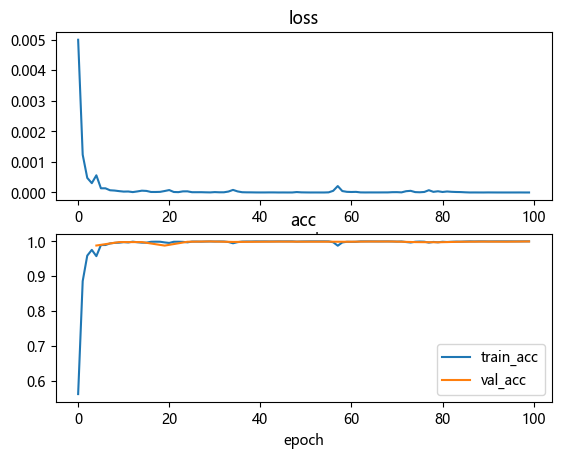

In [122]:
## training the model
device = torch.device(DEVICE if DEVICE>=0 and torch.cuda.is_available() else 'cpu')
loss_list = []
acc_list = []
val_acc_list = []
val_epoch_list = []


model = HybridSN(N_PCA,PATCH_SIZE,class_nums=NUM_CLASS)
model.to(device)
optimizer = torch.optim.Adam(model.parameters(),LR,weight_decay=WEIGHT_DECAY)
loss_func = nn.CrossEntropyLoss()
batch_num = len(train_loader)
train_num = train_loader.dataset.__len__()
val_num = val_loader.dataset.__len__()

fig = plt.figure()
ax1 = fig.add_subplot(2,1,1)
ax2 = fig.add_subplot(2,1,2)
try:
    for e in tqdm(range(EPOCH), desc="Training:"):
        model.train()
        avg_loss = 0.
        train_acc = 0
        for batch_idx, (data, target) in tqdm(enumerate(train_loader),total=batch_num):
            data,target = data.to(device),target.to(device)
            optimizer.zero_grad()
            out = model(data)
            target = target - 1  ## class 0 in out is class 1 in target
            loss = loss_func(out,target)
            loss.backward()
            optimizer.step()
            avg_loss += loss.item()
            _,pred = torch.max(out,dim=1)
            train_acc += (pred == target).sum().item()
        loss_list.append(avg_loss/train_num)
        acc_list.append(train_acc/train_num)
        print(f"epoch {e}/{EPOCH} loss:{loss_list[e]}  acc:{acc_list[e]}")
        ## valuation
        if (e+1)%VAL_EPOCH == 0 or (e+1)==EPOCH:
            val_acc =0
            model.eval()
            for batch_idx, (data, target) in tqdm(enumerate(val_loader),total=len(val_loader)):
                data,target = data.to(device),target.to(device)
                out = model(data)
                target = target - 1  ## class 0 in out is class 1 in target
                _,pred = torch.max(out,dim=1)
                val_acc += (pred == target).sum().item()
            val_acc_list.append(val_acc/val_num)
            val_epoch_list.append(e)
            print(f"epoch {e}/{EPOCH}  val_acc:{val_acc_list[-1]}")
            save_name = os.path.join(SAVE_PATH, f"epoch_{e}_acc_{val_acc_list[-1]:.4f}.pth")
            torch.save(model.state_dict(),save_name)
    ax1.plot(np.arange(e+1),loss_list)
    ax1.set_title('loss')
    ax1.set_xlabel('epoch')
    ax2.plot(np.arange(e+1),acc_list,label = 'train_acc')
    ax2.plot(val_epoch_list,val_acc_list,label = 'val_acc')
    ax2.set_title('acc')
    ax2.set_xlabel('epoch')
    ax2.legend()
    plt.savefig(os.path.join(SAVE_PATH, 'training_curve.png'),
                dpi=150, bbox_inches='tight') 
    np.savetxt(os.path.join(SAVE_PATH, 'loss.csv'), np.array(loss_list))
    np.savetxt(os.path.join(SAVE_PATH, 'train_acc.csv'), np.array(acc_list))
    np.savetxt(os.path.join(SAVE_PATH, 'val_acc.csv'), np.array(val_acc_list))
except Exception as exc:
    print(exc)
finally: 
    print(f'Stop in epoch {e}')


In [123]:
## get best model path and del other models
def get_best_model(acc_list, epoch_list, save_path):
    """get best model path by valuation list

    Args:
        acc_list (list): list of valuation accuracy
        epoch_list (list): list of valuation epoch
        save_path (str): path of save dir

    Returns:
        best_model_path: path of best model
    """
    acc_list = np.array(acc_list)
    epoch_list = np.array(epoch_list)
    best_index = np.argwhere(acc_list==np.max(acc_list))[-1].item()
    best_epoch = epoch_list[best_index]
    best_acc = acc_list[best_index]
    file_name = f"epoch_{best_epoch}_acc_{best_acc:.4f}.pth"
    best_model_path=os.path.join(save_path, file_name)
    print(f"best model:{file_name}")

    # ---------- 安全阀：文件不存在时不做任何删除 ----------
    if not os.path.exists(best_model_path):
        print(f"⚠️ 警告：{file_name} 不存在，跳过删除步骤（避免误删其他模型！）")
        return best_model_path
    # -------------------------------------------------------
    
    ##del save model except best model
    for f in os.listdir(save_path):
        if f[-3:]=='pth' and os.path.join(save_path,f)!=best_model_path:
            os.remove(os.path.join(save_path,f))
    return best_model_path
# 【临时】跳过训练、直接用已保存的 epoch_79 权重做推理
#val_acc_list  = [1.0]
#val_epoch_list = [79]


best model:epoch_99_acc_0.9998.pth


  0%|          | 0/811 [00:00<?, ?it/s]

C:\Users\Administrator\AppData\Local\Temp\ipykernel_17016\2114661837.py:15: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  pred_map += [np.array(pred.detach().cpu() + 1)]   ## class 0 in pred_map is class 1 in gt


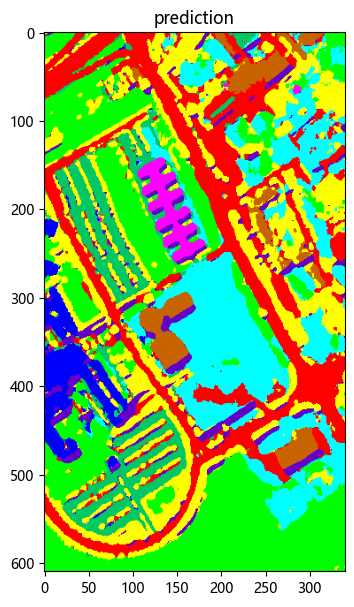

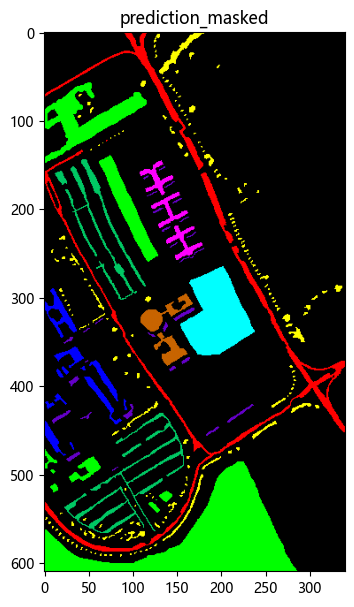

In [124]:
## inferring the whole image
##load best model
best_model_path = get_best_model(val_acc_list,val_epoch_list,SAVE_PATH)

best_model = HybridSN(N_PCA,PATCH_SIZE,class_nums=NUM_CLASS)
best_model.load_state_dict(torch.load(best_model_path))
## inference
best_model.to(device)
best_model.eval()
pred_map = []
for batch_idx, data in tqdm(enumerate(all_loader),total=len(all_loader)):
    data = data.to(device)
    target = best_model(data)
    _, pred = torch.max(target, dim = 1)
    pred_map += [np.array(pred.detach().cpu() + 1)]   ## class 0 in pred_map is class 1 in gt
pred_map = np.asarray(np.hstack(pred_map),dtype=np.uint8).reshape(label.shape[0],label.shape[1])
spectral.imshow(classes=pred_map,title='prediction',figsize=(7,7))
spectral.imshow(classes=pred_map*(label!=0),title='prediction_masked',figsize=(7,7))
spectral.save_rgb(os.path.join(SAVE_PATH,f"prediction.jpg"),pred_map,colors = spectral.spy_colors)
spectral.save_rgb(os.path.join(SAVE_PATH,f"prediction_masked.jpg"),pred_map*(label!=0),colors = spectral.spy_colors)

In [125]:
## classfication report
test_pred = pred_map[test_gt!=0]
test_true = test_gt[test_gt!=0]
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False
from sklearn.metrics import confusion_matrix

# labels 显式指定 1~9，保证顺序固定（即使某类缺失）
cm = confusion_matrix(test_true, test_pred, labels=range(1, NUM_CLASS + 1))
print("混淆矩阵形状:", cm.shape)      # 应为 (9, 9)

print("\n" + "=" * 62)
print("错分流向分析（每个类漏掉的像元去了哪里）")
print("=" * 62)
for i, name in enumerate(class_name):
    row = cm[i].copy()
    row[i] = 0                                  # 抹掉对角线，只留错分
    miss = int(row.sum())
    if miss == 0:
        print(f"{name:<24} 漏 0 个  ✅")
        continue
    print(f"{name:<24} 漏 {miss} 个：")
    for j in np.argsort(-row):                  # 按数量从多到少
        if row[j] > 0:
            print(f"      → 误判为 {class_name[j]:<22} {int(row[j]):>5} 个 "
                  f"({row[j] / miss * 100:.1f}%)")

from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
fig.suptitle(f'Confusion Matrix — {DATASET}', fontsize=16, fontweight='bold')

# 左：原始计数
disp1 = ConfusionMatrixDisplay(cm, display_labels=class_name)
disp1.plot(ax=axes[0], cmap='Blues', values_format='d',
           colorbar=False, xticks_rotation=45)
axes[0].set_title('(a) 原始计数（个）')

# 右：按行归一化 → 每行就是该类的 recall 分布
cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)
disp2 = ConfusionMatrixDisplay(cm_norm, display_labels=class_name)
disp2.plot(ax=axes[1], cmap='Blues', values_format='.4f',
           colorbar=False, xticks_rotation=45)
axes[1].set_title('(b) 按行归一化（对角线 = 各类 recall）')

plt.tight_layout()
plt.savefig(os.path.join(SAVE_PATH, 'confusion_matrix.png'),
            dpi=150, bbox_inches='tight')
plt.close()
print("已保存:", os.path.join(SAVE_PATH, 'confusion_matrix.png'))
            
OA = accuracy_score(test_true,test_pred)
AA = recall_score(test_true,test_pred,average='macro')
kappa = cohen_kappa_score(test_true,test_pred)
report_log = F"OA: {OA}\nAA: {AA}\nKappa: {kappa}\n"
report_log += classification_report(test_true,test_pred,target_names=class_name,digits=4)
print(report_log)
fp = open(os.path.join(SAVE_PATH,'classfication_report.txt'),'w+')
fp.writelines(report_log)
fp.close()
#################################


混淆矩阵形状: (9, 9)

错分流向分析（每个类漏掉的像元去了哪里）
Asphalt                  漏 0 个  ✅
Meadows                  漏 0 个  ✅
Gravel                   漏 0 个  ✅
Trees                    漏 5 个：
      → 误判为 Meadows                    3 个 (60.0%)
      → 误判为 Asphalt                    2 个 (40.0%)
Painted metal sheets     漏 0 个  ✅
Bare Soil                漏 0 个  ✅
Bitumen                  漏 0 个  ✅
Self-Blocking Bricks     漏 0 个  ✅
Shadows                  漏 1 个：
      → 误判为 Painted metal sheets       1 个 (100.0%)
已保存: results\PU_opt2b_mask11\confusion_matrix.png
OA: 0.9997662368021194
AA: 0.9995022852965779
Kappa: 0.9996902318773564
                      precision    recall  f1-score   support

             Asphalt     0.9995    1.0000    0.9997      3979
             Meadows     0.9997    1.0000    0.9999     11190
              Gravel     1.0000    1.0000    1.0000      1259
               Trees     1.0000    0.9973    0.9986      1839
Painted metal sheets     0.9988    1.0000    0.9994       808
           B